# Module 15 · Visualizing Categorical Data and Regression Models

*BUSN 3030E — Python Programming Skills for Business Analytics I*

**Learning objectives.** After this module you will be able to

- compare a numeric variable across categories with strip, swarm, box, and violin plots;
- show estimates and counts per category with bar, point, and count plots;
- visualize linear relationships and their uncertainty with regression plots;
- diagnose a poorly fitting model with polynomial, robust, logistic, and residual plots;
- carry out an open-ended visual analysis of a real dataset.

## 1 · Preparation

Module 14 focused on numeric variables. Many business questions, however, compare **categories**: sales by region, satisfaction by product line, salaries by department. seaborn's `catplot()` (categorical plot) handles these questions with a single interface, just as `relplot()` and `displot()` did; the `kind` parameter selects the type of plot.

| Family | `kind=` | Shows |
|---|---|---|
| Categorical scatter | `"strip"` (default), `"swarm"` | every observation |
| Distribution | `"box"`, `"violin"`, `"boxen"` | the shape of each group |
| Estimate | `"bar"`, `"point"`, `"count"` | one summary number per group |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
tips = sns.load_dataset("tips")

### 1.1 Categorical scatter plots

A strip plot draws every observation and adds a small random horizontal *jitter*, so that points in the same category don't hide one another:

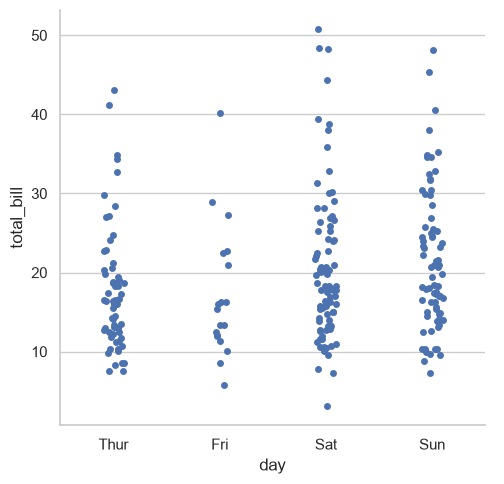

In [2]:
sns.catplot(data=tips, x="day", y="total_bill");

A swarm plot arranges the points so that they never overlap. It shows the distribution more faithfully, but only works for small datasets.

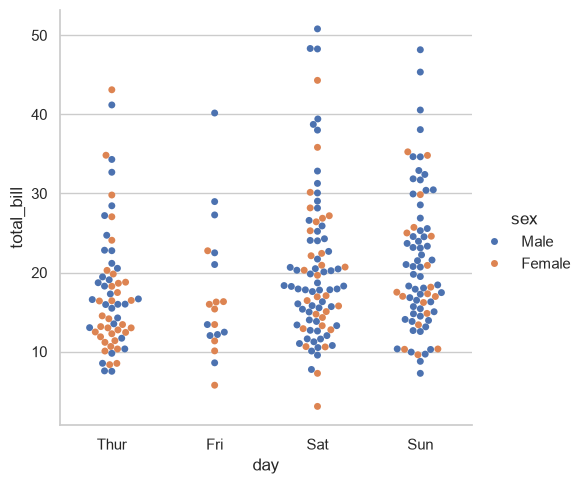

In [3]:
sns.catplot(data=tips, x="day", y="total_bill", hue="sex", kind="swarm");

When category names are long or numerous, put them on the vertical axis by swapping `x` and `y`. The `order` parameter controls the order of the categories.

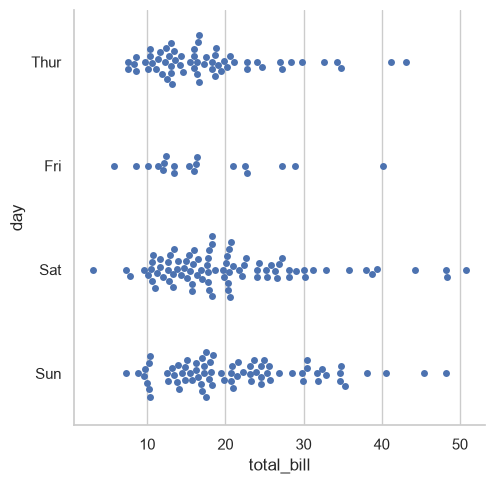

In [4]:
sns.catplot(data=tips, x="total_bill", y="day", kind="swarm", order=["Thur", "Fri", "Sat", "Sun"]);

### 1.2 Distributions within categories

With more data, summaries work better than individual points. A **box plot** shows the median (the line), the quartiles (the box, which holds the middle 50% of observations), and the range of typical values (the whiskers, up to 1.5 times the box height). Points beyond the whiskers are drawn individually as potential outliers.

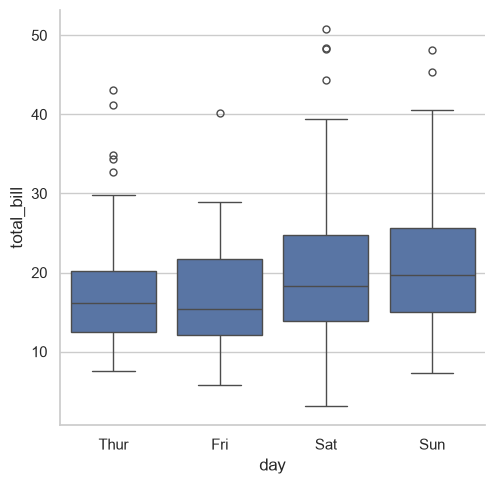

In [5]:
sns.catplot(data=tips, x="day", y="total_bill", kind="box");

Adding `hue` places the boxes of each subgroup side by side (*dodging*):

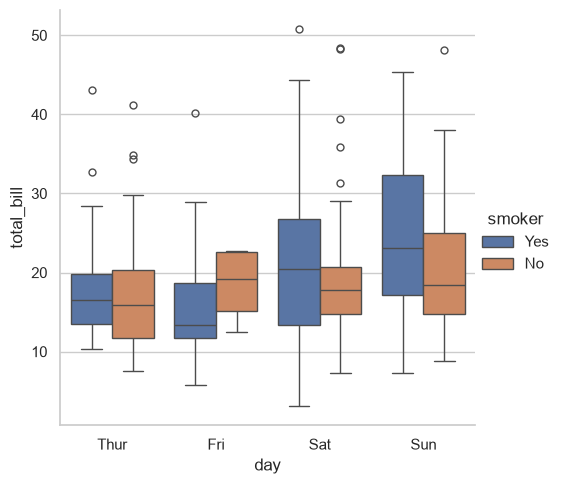

In [6]:
sns.catplot(data=tips, x="day", y="total_bill", hue="smoker", kind="box");

A **violin plot** replaces the box with a mirrored density curve (Module 14), showing the full shape of the distribution. With two `hue` levels, `split=True` puts one half on each side:

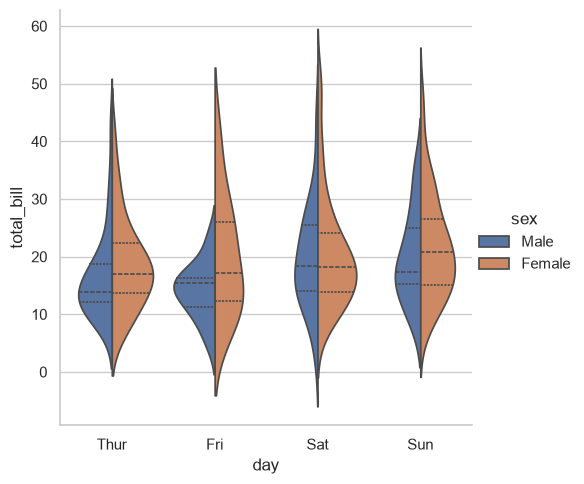

In [7]:
sns.catplot(data=tips, x="day", y="total_bill", hue="sex", kind="violin", split=True, inner="quart");

`inner="quart"` draws the quartiles inside each violin. Layering an axes-level plot on top of a figure-level one combines a summary with the raw data: `catplot` returns a grid whose single panel is `g.ax`.

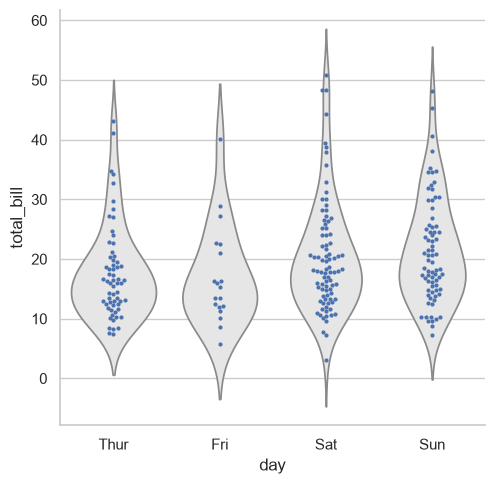

In [8]:
g = sns.catplot(data=tips, x="day", y="total_bill", kind="violin", inner=None, color=".9")
sns.swarmplot(data=tips, x="day", y="total_bill", size=3, ax=g.ax);

### 1.3 Estimates within categories

Sometimes a single number per category, such as an average or a rate, is all the reader needs. A **bar plot** shows the mean of each group, with an error bar for its 95% confidence interval.

The `titanic` dataset records whether each of 891 passengers survived the 1912 disaster. Because `survived` is 0 or 1, its mean is the survival *rate*.

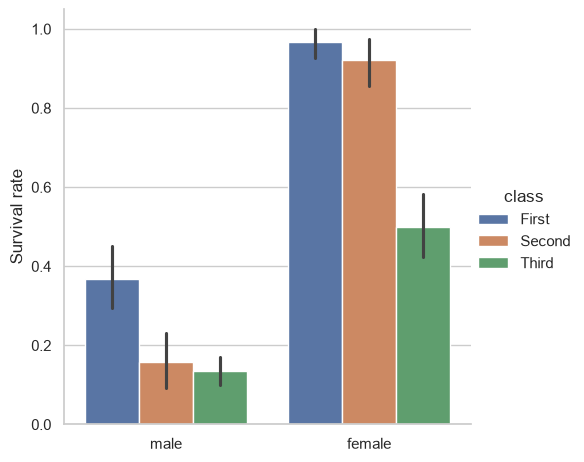

In [9]:
titanic = sns.load_dataset("titanic")
g = sns.catplot(data=titanic, x="sex", y="survived", hue="class", kind="bar")
g.set_axis_labels("", "Survival rate");

A **count plot** shows the number of observations in each category, a histogram for categorical data:

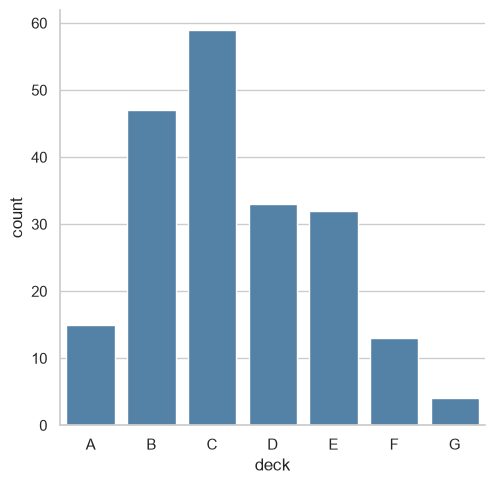

In [10]:
sns.catplot(data=titanic, x="deck", kind="count", color="steelblue");

A **point plot** shows the same estimates as a bar plot, but connects the points of each `hue` level with a line. This makes it easy to compare *changes* across categories: the slopes reveal an interaction.

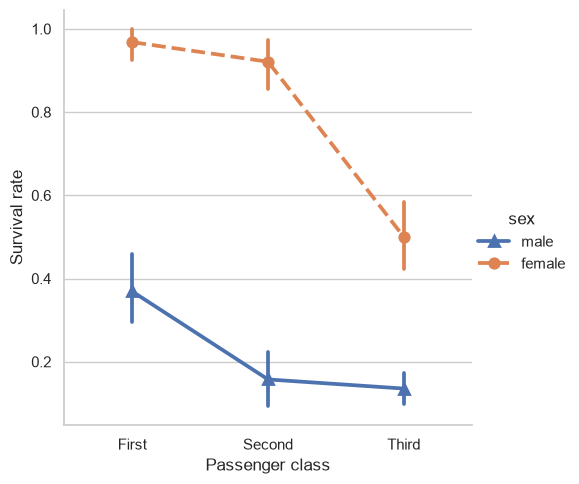

In [11]:
g = sns.catplot(data=titanic, x="class", y="survived", hue="sex", kind="point",
                markers=["^", "o"], linestyles=["-", "--"])
g.set_axis_labels("Passenger class", "Survival rate");

Women's survival rate dropped sharply in third class; men's was low in every class.

### 1.4 Facets

Like `relplot()`, `catplot()` accepts `col` and `row` for small multiples:

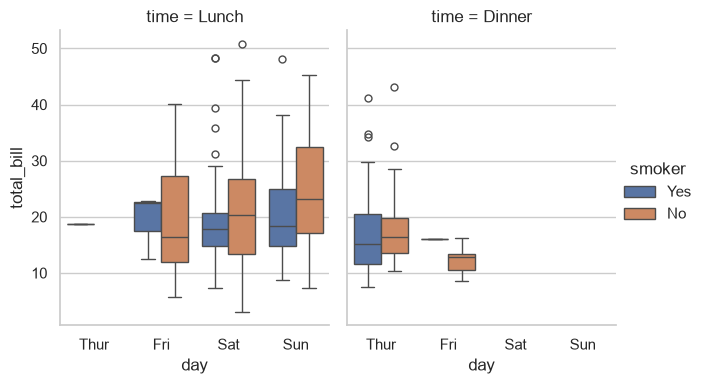

In [12]:
sns.catplot(data=tips, x="day", y="total_bill", hue="smoker", col="time", kind="box", height=4, aspect=0.8);

### 1.5 Regression plots

`sns.lmplot()` draws a scatter plot, fits the linear regression `y ~ x`, and draws the fitted line with a 95% confidence band. It is the visual counterpart of the `statsmodels` regressions of Module 13.

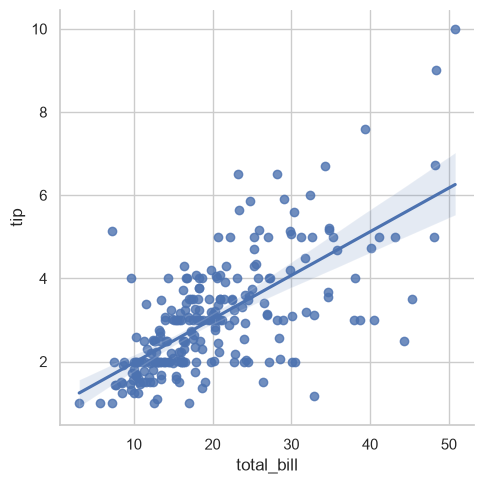

In [13]:
sns.lmplot(data=tips, x="total_bill", y="tip");

When the x variable takes only a few values, `x_jitter` spreads the points for display (the fit is not affected), and `x_estimator` replaces each column of points with its mean and confidence interval:

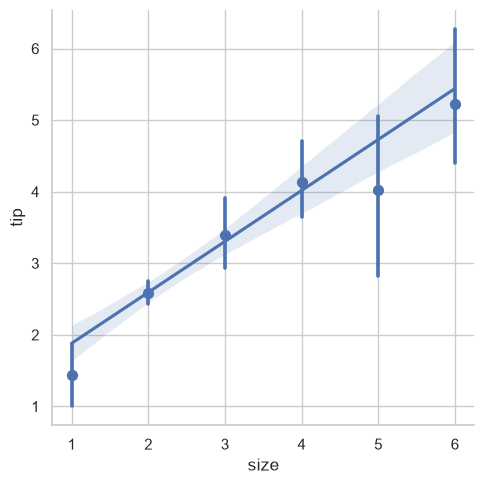

In [14]:
sns.lmplot(data=tips, x="size", y="tip", x_estimator=np.mean);

`hue` and `col` fit a separate line per group, which shows whether the relationship differs between groups:

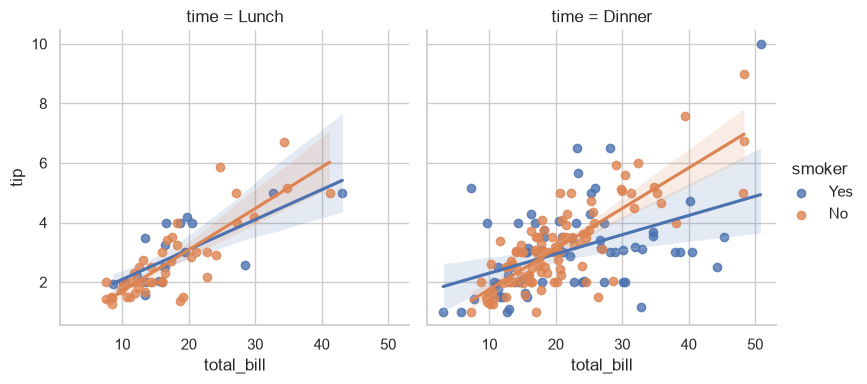

In [15]:
sns.lmplot(data=tips, x="total_bill", y="tip", hue="smoker", col="time", height=4);

### 1.6 When a straight line is not enough

Anscombe's quartet is four small datasets with nearly identical means, variances, correlations, and regression lines, yet completely different patterns. It is a classic reminder to **always plot your data**.

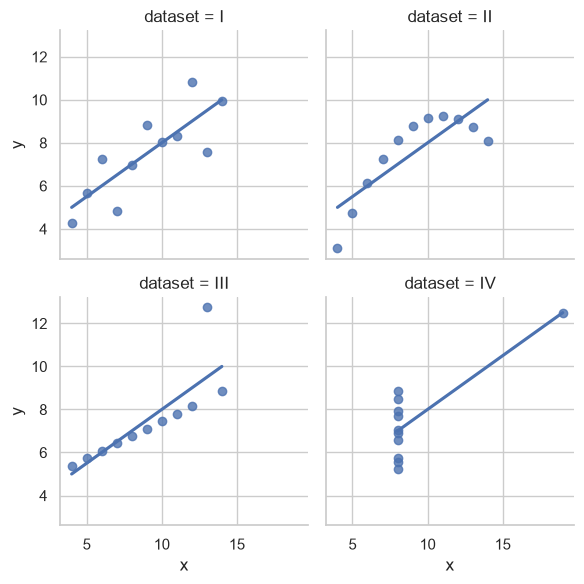

In [16]:
anscombe = sns.load_dataset("anscombe")
sns.lmplot(data=anscombe, x="x", y="y", col="dataset", col_wrap=2, height=3, ci=None);

Dataset I suits a linear model. Dataset II is curved: a polynomial of order 2 fits it perfectly.

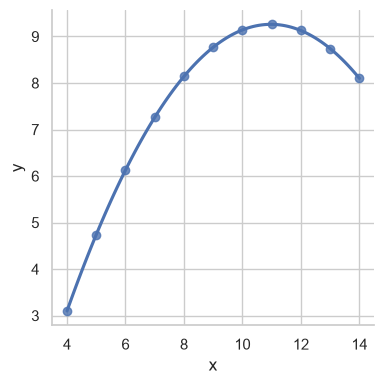

In [17]:
sns.lmplot(data=anscombe[anscombe["dataset"] == "II"], x="x", y="y", order=2, ci=None, height=4);

Dataset III has one outlier that tilts the line. A **robust** regression down-weights large residuals:

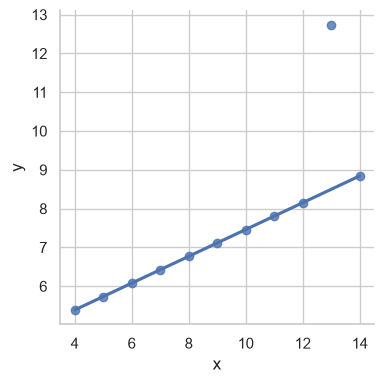

In [18]:
sns.lmplot(data=anscombe[anscombe["dataset"] == "III"], x="x", y="y", robust=True, ci=None, height=4);

A **residual plot** helps diagnose such problems with real data. It plots the errors of a linear fit; if the model is appropriate, they scatter randomly around zero. The U-shape for dataset II reveals the curvature:

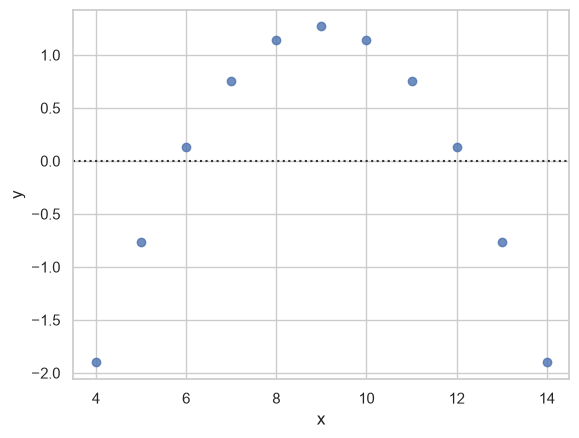

In [19]:
sns.residplot(data=anscombe[anscombe["dataset"] == "II"], x="x", y="y");

**Binary outcomes.** For a 0/1 outcome, `logistic=True` fits the logistic regression of Module 13 and draws the estimated probability. Here, the probability that a tip exceeds 15% of the bill:

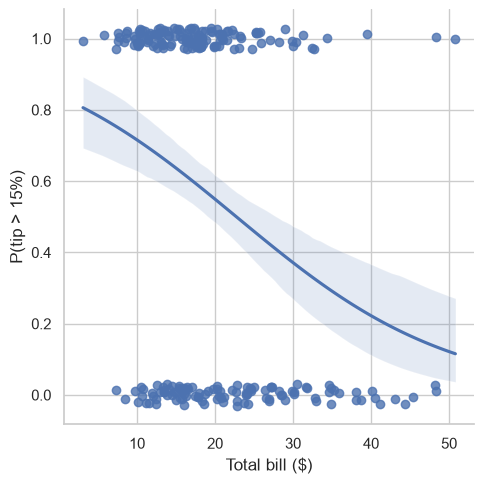

In [20]:
tips["big_tip"] = (tips["tip"] / tips["total_bill"]) > 0.15
g = sns.lmplot(data=tips, x="total_bill", y="big_tip", logistic=True, y_jitter=0.03)
g.set_axis_labels("Total bill ($)", "P(tip > 15%)");

Interestingly, larger bills are *less* likely to receive a generous tip in percentage terms.

## 2 · Warmup

The `planets` dataset lists the more than 1,000 exoplanets (planets outside our solar system) discovered up to 2014, with the year and method of discovery.

In [21]:
planets = sns.load_dataset("planets")
planets.head()

,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300,7.10,77.40,2006
1,Radial Velocity,1,874.774,2.21,56.95,2008
2,Radial Velocity,1,763.000,2.60,19.84,2011
3,Radial Velocity,1,326.030,19.40,110.62,2007
4,Radial Velocity,1,516.220,10.50,119.47,2009


**Exercise 2.1.** Create a bar chart of the number of planets discovered per year.

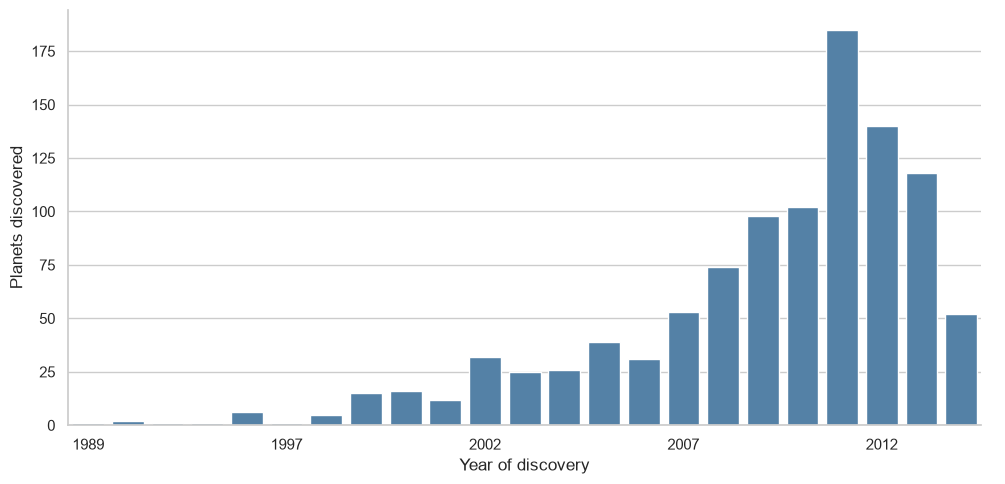

In [22]:
g = sns.catplot(data=planets, x="year", kind="count", color="steelblue", aspect=2)
g.set_axis_labels("Year of discovery", "Planets discovered")
g.set_xticklabels(step=5);

`aspect=2` makes the figure twice as wide as tall, and `set_xticklabels(step=5)` labels every fifth year to avoid overlapping labels.

**Exercise 2.2.** Break down the yearly counts by discovery method, for the years 2001 to 2014.

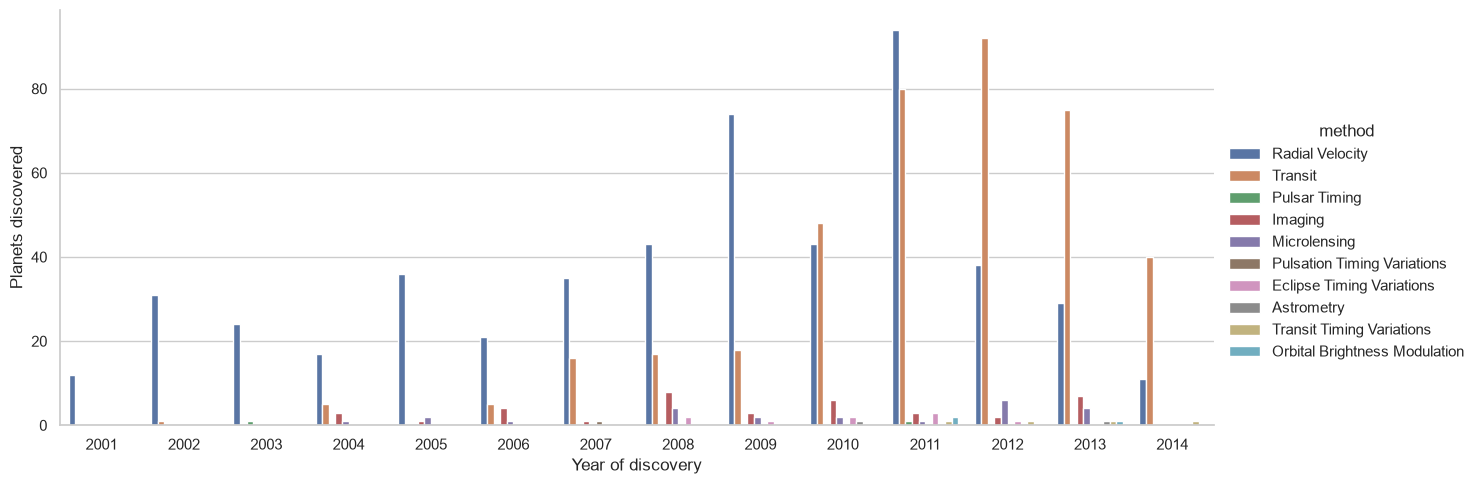

In [23]:
recent = planets[planets["year"] >= 2001]
g = sns.catplot(data=recent, x="year", hue="method", kind="count", aspect=2.5)
g.set_axis_labels("Year of discovery", "Planets discovered");

The *transit* method (detecting the dimming of a star as a planet passes in front of it) took over after the launch of the Kepler space telescope in 2009.

## 3 · Workout: Exploring marathon finishing times

Sports analytics uses data to understand athletic performance. The file `marathon-data.csv` holds the results of more than 37,000 runners of a large marathon: their age, gender, the time at the half-way mark (`split`), and the finishing time (`final`).

In [24]:
DATA_URL = "https://raw.githubusercontent.com/hanisaf/python-programming-skills/main/data/"
marathon = pd.read_csv(DATA_URL + "marathon-data.csv")
marathon.head()

,age,gender,split,final
0,33,M,01:05:38,02:08:51
1,32,M,01:06:26,02:09:28
2,31,M,01:06:49,02:10:42
3,38,M,01:06:16,02:13:45
4,31,M,01:06:32,02:13:59


In [25]:
marathon.dtypes

age       int64
gender      str
split       str
final       str
dtype: object

**Exercise 3.1.** The times are text (type `str`, or `object` in pandas 2) of the form `hh:mm:ss`. Convert them to seconds.

**Solution.** `pd.to_timedelta()` converts the text to durations, and the `.dt.total_seconds()` accessor expresses each duration in seconds:

In [26]:
marathon["split_sec"] = pd.to_timedelta(marathon["split"]).dt.total_seconds()
marathon["final_sec"] = pd.to_timedelta(marathon["final"]).dt.total_seconds()
marathon.head()

,age,gender,split,final,split_sec,final_sec
0,33,M,01:05:38,02:08:51,3938.0,7731.0
1,32,M,01:06:26,02:09:28,3986.0,7768.0
2,31,M,01:06:49,02:10:42,4009.0,7842.0
3,38,M,01:06:16,02:13:45,3976.0,8025.0
4,31,M,01:06:32,02:13:59,3992.0,8039.0


**Exercise 3.2.** How do half-way times relate to finishing times?

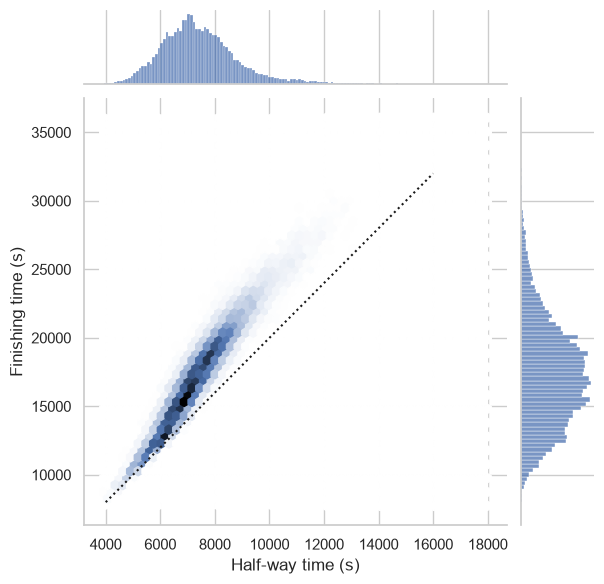

In [27]:
g = sns.jointplot(data=marathon, x="split_sec", y="final_sec", kind="hex")
g.ax_joint.plot([4000, 16000], [8000, 32000], ":k")   # steady pace: final = 2 x split
g.set_axis_labels("Half-way time (s)", "Finishing time (s)");

The dotted line marks a perfectly steady pace, where the finishing time is exactly twice the half-way time. Nearly all runners are above it: they ran the second half more slowly than the first.

**Exercise 3.3.** Measure how much each runner slowed down, and plot the distribution.

We define the **split fraction** as $1 - 2 \times \text{split} / \text{final}$. It is 0 for a steady pace, positive when the second half was slower, and negative for the rare runners who ran the second half faster (a *negative split*).

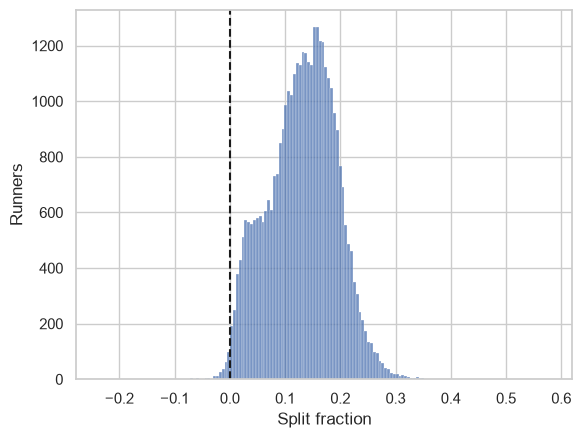

In [28]:
marathon["split_frac"] = 1 - 2 * marathon["split_sec"] / marathon["final_sec"]

ax = sns.histplot(data=marathon, x="split_frac")
ax.axvline(0, color="k", linestyle="--")
ax.set(xlabel="Split fraction", ylabel="Runners");

In [29]:
negative = (marathon["split_frac"] < 0).sum()
print(f"{negative} of {len(marathon):,} runners ({negative / len(marathon):.1%}) ran a negative split")

251 of 37,250 runners (0.7%) ran a negative split


`histplot()` is the axes-level version of `displot()`; it returns a matplotlib axes object, which offers methods such as `axvline()` (a vertical line) and `set()`.

**Exercise 3.4.** Is the split fraction related to the other variables? Look at all relationships, by gender.

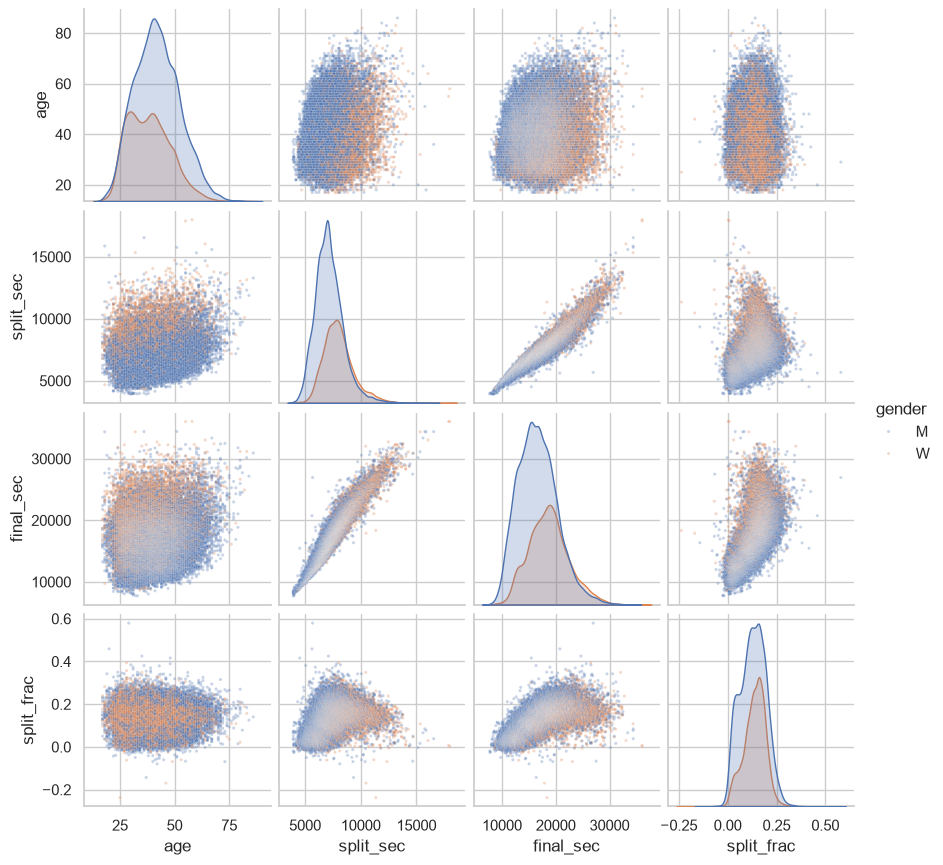

In [30]:
sns.pairplot(data=marathon, vars=["age", "split_sec", "final_sec", "split_frac"],
             hue="gender", plot_kws={"alpha": 0.3, "s": 5}, height=2.2);

The split fraction does not depend much on age, but it does depend on the finishing time: faster runners keep a more even pace.

**Exercise 3.5.** Compare the split fraction of men and women.

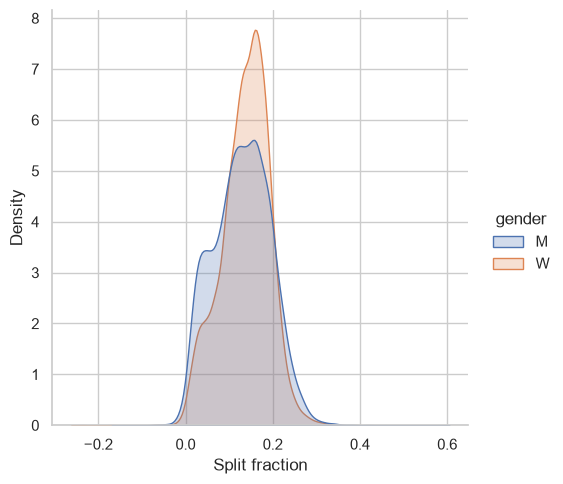

In [31]:
g = sns.displot(data=marathon, x="split_frac", hue="gender", kind="kde", fill=True, common_norm=False)
g.set_axis_labels("Split fraction", "Density");

Many more men than women run close to an even split. Does this hold at every age? Group the runners by decade of age, then compare the distributions with split violins.

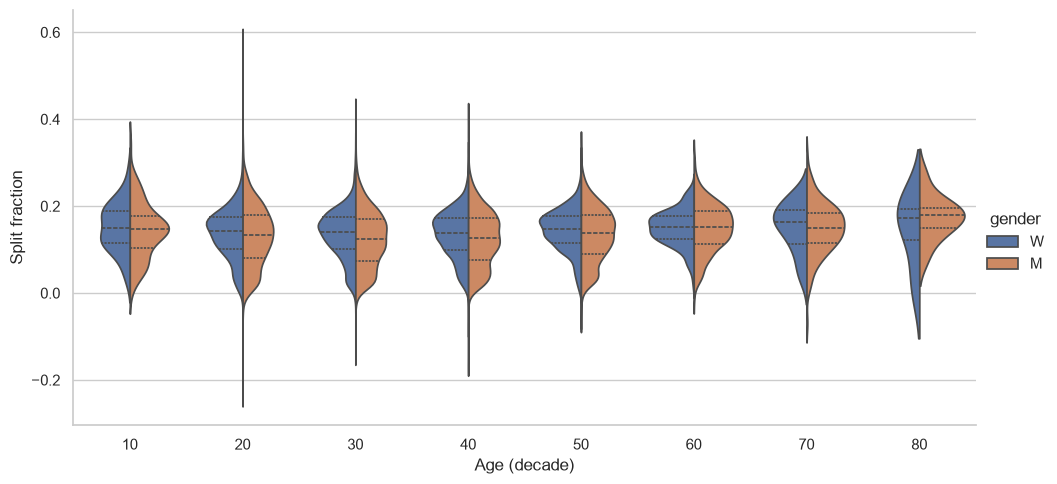

In [32]:
marathon["age_decade"] = (marathon["age"] // 10) * 10

g = sns.catplot(data=marathon, x="age_decade", y="split_frac", hue="gender",
                kind="violin", split=True, inner="quart", aspect=2)
g.set_axis_labels("Age (decade)", "Split fraction");

The difference between men and women is concentrated among runners in their 20s to 50s. The oldest group seems to break the pattern, but it is tiny, so its violins rest on very few observations:

In [33]:
marathon["age_decade"].value_counts().sort_index()

age_decade
10      131
20     5442
30    11994
40    12263
50     5817
60     1437
70      151
80       15
Name: count, dtype: int64

**Exercise 3.6.** Who are the runners with the most even pace? Fit a regression of the split fraction on the finishing time, separately for men and women.

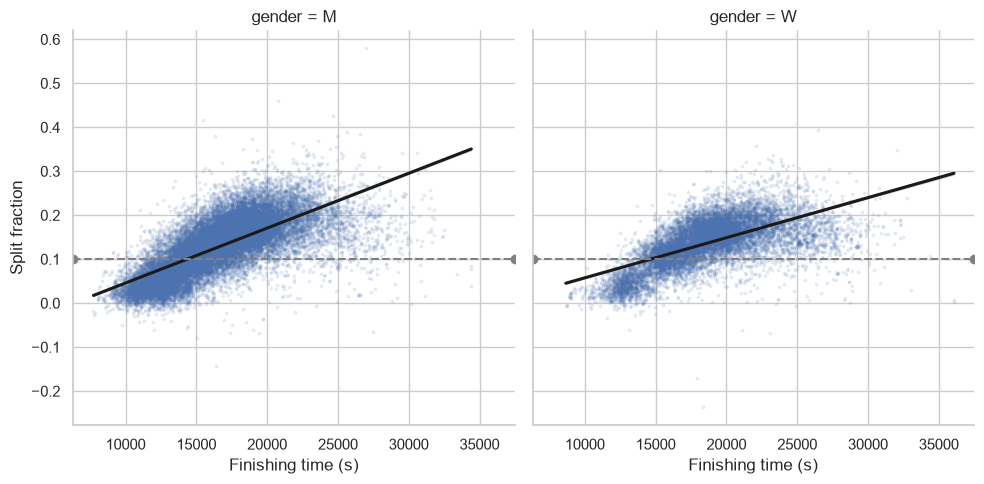

In [34]:
g = sns.lmplot(data=marathon, x="final_sec", y="split_frac", col="gender",
               scatter_kws={"alpha": 0.1, "s": 3}, line_kws={"color": "k"})
g.refline(y=0.1)
g.set_axis_labels("Finishing time (s)", "Split fraction");

Runners who finish faster have smaller split fractions. The dashed reference line marks a split fraction of 0.1, at which the second half takes about 20% longer than the first. Runners finishing in under roughly 15,000 seconds (just over four hours) mostly stay below it, while slower runners tend to fade in the second half.

## Summary

| Function | Draws | Key options |
|---|---|---|
| `sns.catplot()` | categorical plots | `kind` = `strip`, `swarm`, `box`, `violin`, `boxen`, `bar`, `point`, `count`; `hue`, `order`, `col` |
| `sns.lmplot()` | scatter plot with regression fit | `hue`, `col`, `order`, `robust`, `logistic`, `x_estimator`, `ci` |
| `sns.residplot()` | residuals of a linear fit | |
| axes-level functions | single panels to combine | `sns.swarmplot`, `sns.histplot`, `ax=` |
| grid methods | labels, reference lines | `g.set_axis_labels()`, `g.set_xticklabels()`, `g.refline()` |

**Course wrap-up.** Over fifteen modules you have moved through the whole analytics pipeline: writing Python, organizing data in built-in structures and DataFrames, summarizing and modeling it with statistics, and communicating results with visualizations. These skills are the foundation for more advanced analytics courses and for any data-driven role.